# 01 — Análise exploratória e qualidade dos dados

**Projeto:** Segmentação e risco de inadimplência de clientes de crédito  
**Dataset:** *Default of Credit Card Clients* (UCI, dados históricos de 2005)  
**Objetivo:** verificar estrutura, qualidade, distribuição do alvo e associações iniciais; estabelecer cuidados contra vazamento de dados.

> Este notebook documenta uma simulação para portfólio. Nenhuma conclusão deve ser interpretada como recomendação real de crédito sem validação adicional.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

### Importação de bibliotecas

Importamos as ferramentas para manipulação de dados (`pandas` e `numpy`), visualização (`matplotlib` e `seaborn`) e acesso ao conjunto de dados da UCI (`ucimlrepo`). Esta célula apenas prepara o ambiente; não altera nem treina dados.

In [31]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

dataset = fetch_ucirepo(id=350)
X = dataset.data.features.copy()
y = dataset.data.targets.copy()

### Configuração e carregamento da base

Definiu-se a aparência dos gráficos e carregamos o dataset **Default of Credit Card Clients**, da UCI. Separamos, inicialmente, as variáveis explicativas (`X`) da variável-alvo (`y`). A base representa clientes de cartão de crédito em Taiwan em 2005; o cenário de negócio é uma **simulação**, não uma base de cooperados brasileiros.

In [32]:
# Padronizacao do nome e da target
colunas = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

X = X.rename(columns=colunas)
y.columns = ["inadimplente"]

df = pd.concat([X, y], axis=1)

print("Dimensoes:", df.shape)
df.head()

Dimensoes: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,inadimplente
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Padronização dos nomes e consolidação

Renomeamos `X1` a `X23` para nomes que identificam limite de crédito, atributos demográficos, histórico de status de pagamento, valores de faturas e pagamentos. A coluna-alvo passa a se chamar `inadimplente` (`1` = inadimplência no mês seguinte; `0` = caso contrário). **Resultado: 30.000 registros e 24 colunas** (23 atributos e um alvo). Esta renomeação não usa a variável-alvo para construir atributos e, portanto, não configura vazamento.

**Regra temporal:** para a classificação, foi simulada uma previsão depois que os registros de setembro já estão disponíveis, mas antes de observar a inadimplência do mês seguinte.

In [33]:
#Auditoria da qualidade dos dados

print("Tipos das colunas:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isna().sum().sort_values(ascending=False))

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nDistribuicao do alvo:")
print(df["inadimplente"].value_counts())

print("\nPercentuais:")
print(
    df["inadimplente"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nCategorias encontradas:")
for coluna in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    print(coluna, sorted(df[coluna].dropna().unique()))


Tipos das colunas:
LIMIT_BAL       int64
SEX             int64
EDUCATION       int64
MARRIAGE        int64
AGE             int64
PAY_0           int64
PAY_2           int64
PAY_3           int64
PAY_4           int64
PAY_5           int64
PAY_6           int64
BILL_AMT1       int64
BILL_AMT2       int64
BILL_AMT3       int64
BILL_AMT4       int64
BILL_AMT5       int64
BILL_AMT6       int64
PAY_AMT1        int64
PAY_AMT2        int64
PAY_AMT3        int64
PAY_AMT4        int64
PAY_AMT5        int64
PAY_AMT6        int64
inadimplente    int64
dtype: object

Valores ausentes:
LIMIT_BAL       0
SEX             0
EDUCATION       0
MARRIAGE        0
AGE             0
PAY_0           0
PAY_2           0
PAY_3           0
PAY_4           0
PAY_5           0
PAY_6           0
BILL_AMT1       0
BILL_AMT2       0
BILL_AMT3       0
BILL_AMT4       0
BILL_AMT5       0
BILL_AMT6       0
PAY_AMT1        0
PAY_AMT2        0
PAY_AMT3        0
PAY_AMT4        0
PAY_AMT5        0
PAY_AMT6        0
inadim

### Auditoria inicial da qualidade dos dados

**Resultados observados:** todas as 24 colunas são inteiras, não há valores ausentes (`NaN`) e existem **35 duplicatas completas** nas colunas disponíveis. A classe positiva possui **6.636 registros (22,12%)**, contra **23.364 (77,88%)** da classe negativa. Portanto, acurácia isolada pode ser enganosa; na classificação, avaliaremos principalmente *recall*, *precision*, F1 e métricas apropriadas ao desbalanceamento.

Os códigos de `EDUCATION` e `MARRIAGE` incluem valores não usuais; `PAY_0` inclui códigos negativos. Esses valores exigem interpretação e documentação antes de qualquer recodificação. Não há motivo para imputar valores ausentes nesta base.

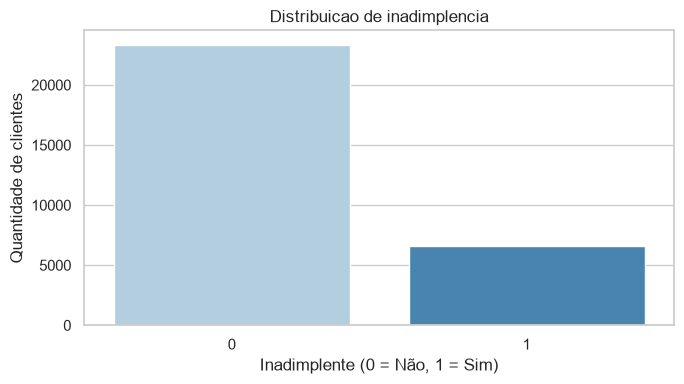

In [34]:
#visualizacao do desbalanceamento
fig, ax = plt.subplots(figsize=(7, 4))

sns.countplot(
    data=df,
    x="inadimplente",
    hue="inadimplente",
    palette="Blues",
    legend=False,
    ax=ax
)

ax.set_title("Distribuicao de inadimplencia")
ax.set_xlabel("Inadimplente (0 = Não, 1 = Sim)")
ax.set_ylabel("Quantidade de clientes")

plt.tight_layout()
plt.show()

### Visualização do desbalanceamento

O gráfico mostra que a maioria dos registros é da classe `0` (sem inadimplência), mas a classe `1` ainda representa uma parcela relevante (**22,12%**). Um classificador que sempre respondesse `0` teria **77,88% de acurácia** e **recall zero** para inadimplentes. O objetivo não é somente acertar a classe mais frequente, mas identificar clientes com risco elevado de maneira útil ao negócio.

In [35]:

from sklearn.model_selection import StratifiedGroupKFold

X = df.drop(columns=["inadimplente", "ID"], errors="ignore")
y = df["inadimplente"]

# Mesmo conjunto de atributos = mesmo grupo
grupos = pd.util.hash_pandas_object(
    X, index=False
)

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=grupos)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("Taxa treino:", round(y_train.mean() * 100, 2), "%")
print("Taxa teste:", round(y_test.mean() * 100, 2), "%")

assert set(grupos.iloc[train_idx]).isdisjoint(
    set(grupos.iloc[test_idx])
)


Treino: (24000, 23)
Teste: (6000, 23)
Taxa treino: 22.12 %
Taxa teste: 22.12 %


### Separação de treino e teste sem perfis idênticos nos dois conjuntos

Foi utilizado `StratifiedGroupKFold` com agrupamento por hash das **23 características**, de modo que perfis com atributos idênticos permaneçam no mesmo lado da separação. O resultado salvo foi **24.000 observações de treino** e **6.000 de teste**, com **22,12% de inadimplência** em ambos. A checagem confirma que não há hashes de perfis compartilhados.

**Nota metodológica:** perfis iguais não provam que se trate da mesma pessoa; o agrupamento é uma precaução conservadora, já que o identificador original não está entre as colunas carregadas. `StratifiedGroupKFold` tenta equilibrar classes, mas não garante proporções exatas em toda execução. O conjunto de teste será preservado para avaliação final. Para validação cruzada posterior, também devemos respeitar os grupos dentro do treino; idealmente, usar a combinação de pipeline e divisão por grupos.

In [36]:

print("Duplicatas:", df.duplicated().sum())

duplicatas = df[df.duplicated(keep=False)]

print("Registros envolvidos:", len(duplicatas))

treino = X_train.copy()
treino["inadimplente"] = y_train

teste = X_test.copy()
teste["inadimplente"] = y_test

sobreposicao = pd.merge(
    treino.drop_duplicates(),
    teste.drop_duplicates(),
    how="inner",
    on=list(df.columns)
)

print("Perfis identicos entre treino e teste:",
      len(sobreposicao))

duplicatas.head(10)


Duplicatas: 35
Registros envolvidos: 70
Perfis identicos entre treino e teste: 0


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,inadimplente
18,360000,2,1,1,49,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,0
627,230000,1,1,1,39,-1,-1,-1,-1,-1,-1,660,660,660,660,660,660,660,660,660,660,660,660,0
839,500000,1,1,1,43,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,1
1093,360000,1,2,1,41,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,1
1211,160000,2,3,2,26,-1,-1,-1,-1,-1,-1,390,390,390,390,390,390,390,390,390,390,390,390,0
1601,150000,2,1,1,31,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,0
1759,50000,1,2,2,26,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,0
1964,150000,2,1,1,38,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,1
1980,150000,2,1,1,38,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,1
2621,210000,2,1,2,39,1,-2,-2,-2,-2,-2,0,0,0,0,0,0,0,0,0,0,0,0,0


### Investigação de registros duplicados

Foram encontradas **35 linhas repetidas** (`duplicated()`), correspondentes a **70 registros envolvidos** quando incluímos a primeira ocorrência de cada par. Com o *split* atualizado, o resultado salvo é **0 perfis completos idênticos entre treino e teste**. Não excluímos automaticamente as duplicatas: sem um identificador individual, pessoas diferentes podem ter exatamente os mesmos atributos. Além disso, a comparação feita aqui inclui o alvo; a verificação de hash da célula anterior é mais rigorosa, pois compara apenas as variáveis explicativas.

In [37]:

categoricas = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0"
]

for coluna in categoricas:
    print(f"\n===== {coluna} =====")

    frequencias = (
        df[coluna]
        .value_counts()
        .sort_index()
        .rename_axis("Categoria")
        .reset_index(name="Quantidade")
    )

    frequencias["Percentual"] = (
        frequencias["Quantidade"]
        / len(df) * 100
    ).round(2)

    display(frequencias)



===== SEX =====


,Categoria,Quantidade,Percentual
0,1,11888,39.63
1,2,18112,60.37



===== EDUCATION =====


,Categoria,Quantidade,Percentual
0,0,14,0.05
1,1,10585,35.28
2,2,14030,46.77
3,3,4917,16.39
4,4,123,0.41
5,5,280,0.93
6,6,51,0.17



===== MARRIAGE =====


,Categoria,Quantidade,Percentual
0,0,54,0.18
1,1,13659,45.53
2,2,15964,53.21
3,3,323,1.08



===== PAY_0 =====


,Categoria,Quantidade,Percentual
0,-2,2759,9.20
1,-1,5686,18.95
2,0,14737,49.12
3,1,3688,12.29
4,2,2667,8.89
5,3,322,1.07
6,4,76,0.25
7,5,26,0.09
8,6,11,0.04
9,7,9,0.03


### Frequências das categorias codificadas

`SEX` assume os códigos `1` e `2`. Em `EDUCATION`, aparecem códigos `0`, `5` e `6` (respectivamente **14, 280 e 51 registros**) cuja interpretação não é inequívoca na documentação resumida da base. `MARRIAGE=0` aparece em **54 registros**. Para `PAY_0`, destacam-se `-2` (**2.759**), `-1` (**5.686**) e `0` (**14.737**), além de status de atraso positivos.

**Decisão nesta etapa:** manter os códigos brutos e documentar as categorias especiais. Embora inteiras, algumas dessas colunas representam **categorias**, não grandezas contínuas.

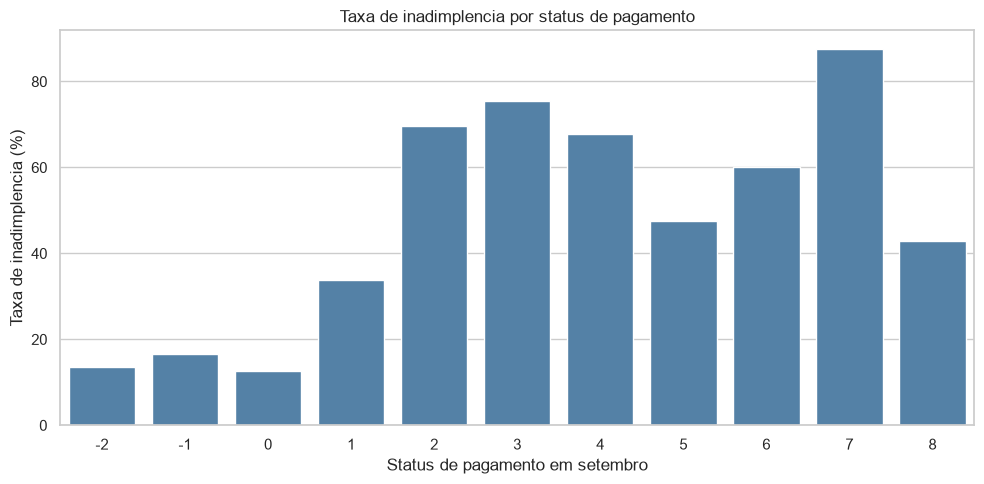

,PAY_0,mean,count
0,-2,13.56,2220
1,-1,16.62,4507
2,0,12.70,11805
3,1,33.74,2943
4,2,69.74,2148
5,3,75.47,265
6,4,67.80,59
7,5,47.62,21
8,6,60.00,10
9,7,87.50,8


In [38]:
# EDA visual
eda_treino = X_train.copy()
eda_treino["inadimplente"] = y_train

taxa_atraso = (
    eda_treino.groupby("PAY_0")["inadimplente"]
    .agg(["mean", "count"])
    .reset_index()
)

taxa_atraso["mean"] *= 100

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=taxa_atraso,
    x="PAY_0",
    y="mean",
    color="steelblue",
    ax=ax
)

ax.set_title("Taxa de inadimplencia por status de pagamento")
ax.set_xlabel("Status de pagamento em setembro")
ax.set_ylabel("Taxa de inadimplencia (%)")

plt.tight_layout()
plt.show()

display(taxa_atraso.round(2))


### Relação entre status de pagamento e inadimplência

No **conjunto de treino**, a inadimplência observada é de **12,70%** para `PAY_0=0`, **33,74%** para `PAY_0=1` e **69,74%** para `PAY_0=2`. Os resultados sugerem forte associação entre histórico recente de pagamento e inadimplência posterior — **não demonstram causalidade**.

Os status extremos têm poucas observações (por exemplo, `PAY_0=7` contém somente **8 registros** no treino). Portanto, suas taxas são instáveis e não devem fundamentar conclusões de negócio isoladamente. `PAY_0` é informação de setembro; seu uso na classificação é coerente com a data de previsão que definimos. **Este gráfico descreve o treino; não utiliza o teste para escolher regras de modelagem.**

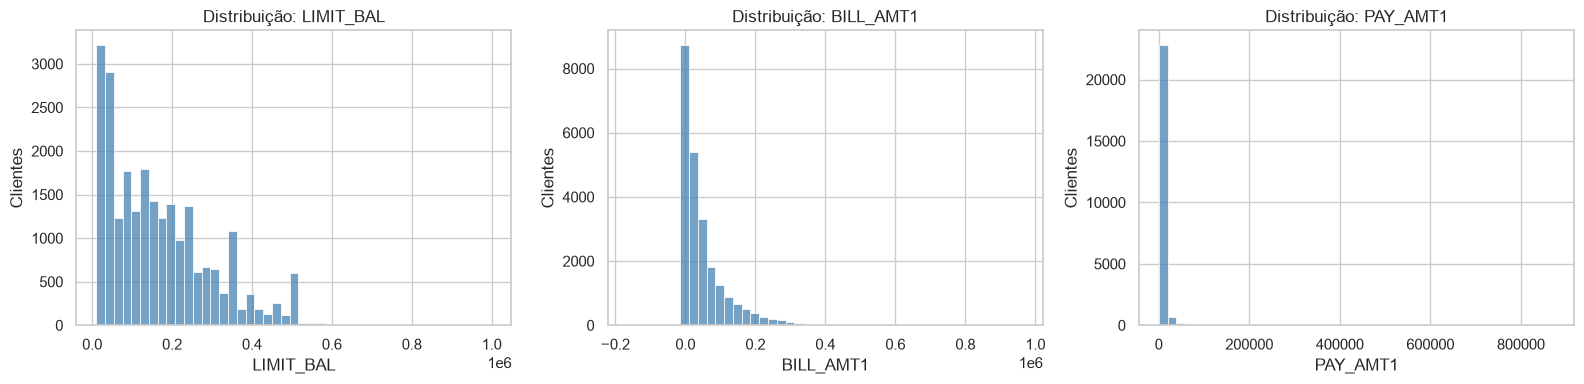

Resumo financeiro (treino):


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
LIMIT_BAL,24000.0,167807.90,129892.17,10000.0,10000.00,50000.0,140000.0,240000.00,430500.00,500000.00,1000000.0
BILL_AMT1,24000.0,51473.29,73917.20,-165580.0,-84.05,3612.5,22619.0,67597.25,201421.15,350756.80,964511.0
PAY_AMT1,24000.0,5664.38,16510.93,0.0,0.00,1000.0,2122.0,5012.00,18488.60,66026.48,873552.0


In [ ]:
# EDA financeira: distribuições no conjunto de treino
financeiras = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, coluna in zip(axes, financeiras):
    sns.histplot(data=eda_treino, x=coluna, bins=45, ax=ax, color="steelblue")
    ax.set_title(f"Distribuicao: {coluna}")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Clientes")
plt.tight_layout()
plt.show()

print("Resumo financeiro (treino):")
display(eda_treino[financeiras].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T.round(2))

### Distribuição das variáveis financeiras

Este bloco examina os valores de limite de crédito, fatura e pagamento mais recentes **somente no treino**. Compare média e mediana para detectar assimetria e os percentis 95/99 para dimensionar a cauda. Valores extremos não são excluídos automaticamente: em finanças, podem ser legítimos. **Registrar as conclusões numéricas depois de executar esta célula.**

,variavel,minimo,maximo,outliers_iqr,percentual
10,PAY_AMT4,0,621000,2394,9.98
12,PAY_AMT6,0,527143,2380,9.92
11,PAY_AMT5,0,426529,2353,9.80
7,PAY_AMT1,0,873552,2204,9.18
8,PAY_AMT2,0,1684259,2196,9.15
5,BILL_AMT5,-81334,927171,2162,9.01
6,BILL_AMT6,-209051,961664,2128,8.87
4,BILL_AMT4,-170000,891586,2079,8.66
9,PAY_AMT3,0,896040,2066,8.61
3,BILL_AMT3,-157264,1664089,1964,8.18


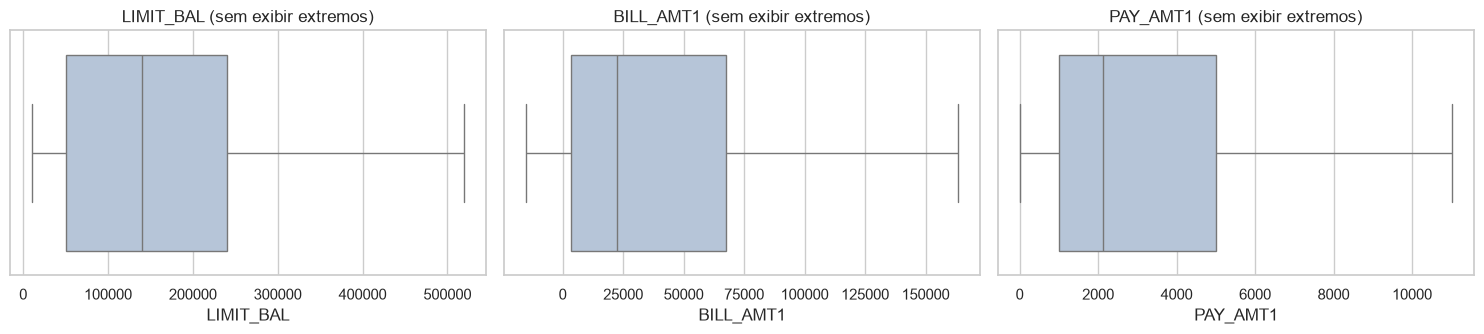

In [40]:
# Outliers: diagnóstico pelo intervalo interquartil (IQR), sem remoção
colunas_financeiras = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
resumo_outliers = []
for coluna in colunas_financeiras:
    serie = eda_treino[coluna]
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    qtd = ((serie < inferior) | (serie > superior)).sum()
    resumo_outliers.append({
        "variavel": coluna, "minimo": serie.min(), "maximo": serie.max(),
        "outliers_iqr": int(qtd), "percentual": round(100 * qtd / len(serie), 2)
    })
resumo_outliers = pd.DataFrame(resumo_outliers).sort_values("percentual", ascending=False)
display(resumo_outliers)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, coluna in zip(axes, ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]):
    sns.boxplot(x=eda_treino[coluna], ax=ax, color="lightsteelblue", showfliers=False)
    ax.set_title(f"{coluna} (sem exibir extremos)")
plt.tight_layout()
plt.show()

### Valores extremos e decisão de tratamento

A regra IQR é **um diagnóstico estatístico**, não uma definição de erro: pagamentos e faturas podem ter distribuições muito assimétricas. Os boxplots escondem apenas a **visualização** de pontos extremos (`showfliers=False`), preservando todos os valores na base. Não haverá remoção ou *winsorização* nesta etapa. Na modelagem, escalonamento e outras transformações deverão ser aprendidos exclusivamente no treino de cada *fold*. **Preencher interpretações específicas após executar a célula.**

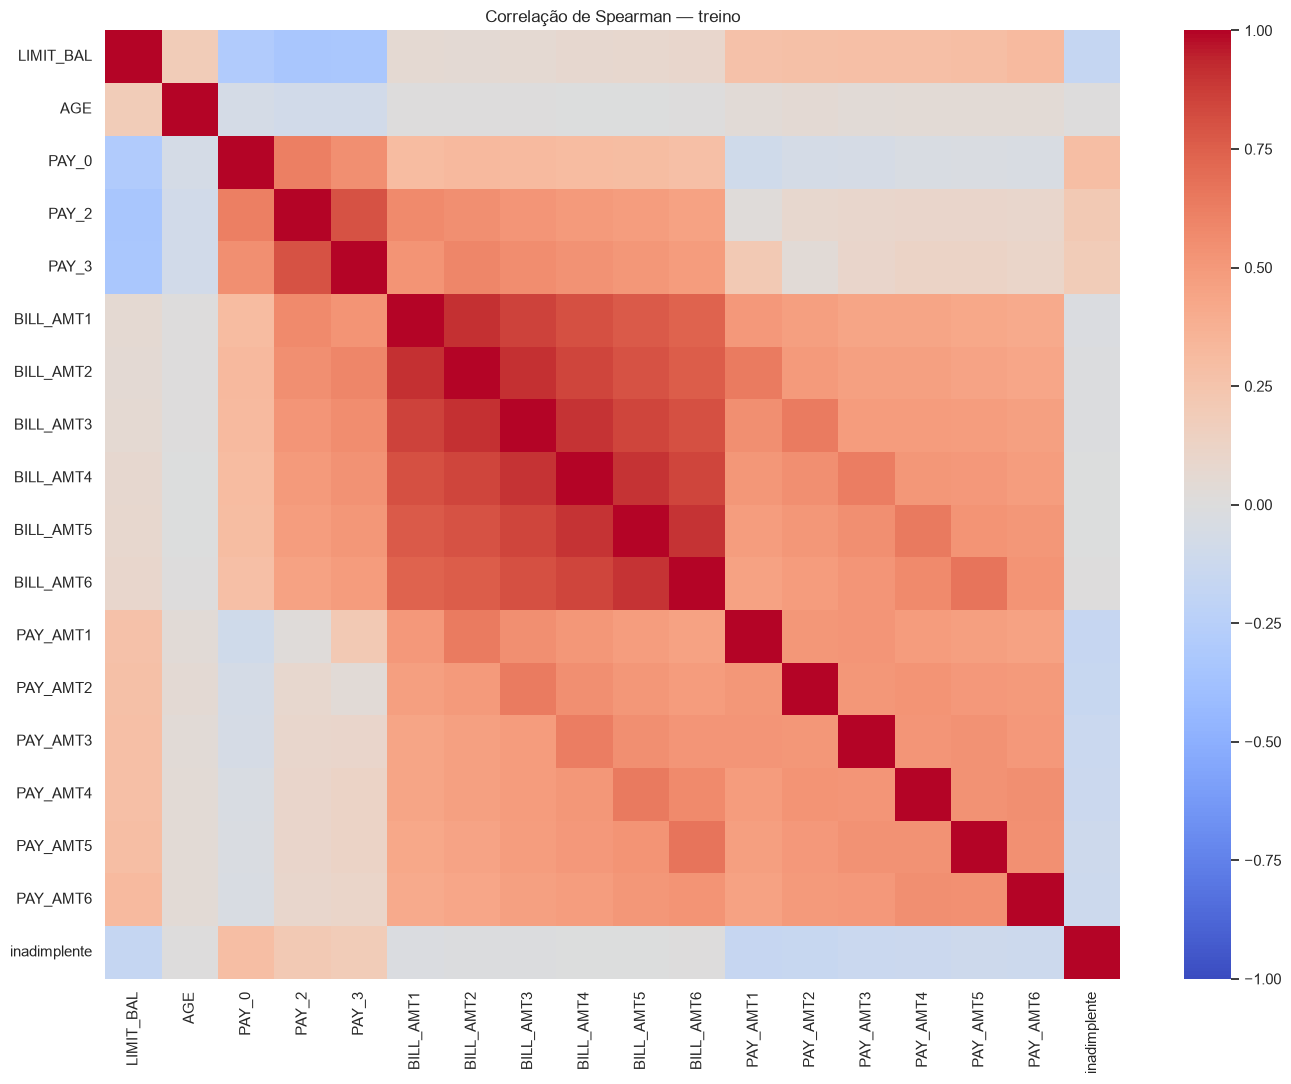

Associações com inadimplência (Spearman, treino):


PAY_0        0.294
PAY_2        0.218
PAY_3        0.193
LIMIT_BAL   -0.164
PAY_AMT1    -0.158
PAY_AMT2    -0.150
PAY_AMT3    -0.137
PAY_AMT4    -0.128
PAY_AMT6    -0.121
PAY_AMT5    -0.114
BILL_AMT1   -0.021
BILL_AMT2   -0.012
BILL_AMT3   -0.009
BILL_AMT4   -0.006
BILL_AMT5   -0.005
BILL_AMT6    0.002
AGE          0.001
Name: inadimplente, dtype: float64

In [ ]:
# Correlação entre variáveis financeiras e atraso (treino)
variaveis_corr = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)] + ["inadimplente"]
correlacoes = eda_treino[variaveis_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(correlacoes, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlacaoo de Spearman — treino")
plt.tight_layout()
plt.show()

print("Associacoes com inadimplencia (Spearman, treino):")
display(correlacoes["inadimplente"].drop("inadimplente").sort_values(key=lambda x: x.abs(), ascending=False).round(3))

### Correlação e interpretação

A correlação de Spearman explora associações monotônicas, inclusive em variáveis assimétricas. As correlações com a inadimplência são **exploratórias**, não evidência de causalidade. Faturas de meses vizinhos podem ser fortemente associadas, o que será relevante para o pré-processamento e para a interpretação da segmentação. **Após execução, registrar quais variáveis se destacaram; não selecionar hiperparâmetros olhando o teste.**

LIMIT_BAL               AGE        BILL_AMT1           PAY_AMT1  \
                median       mean median   mean    median      mean   median   
inadimplente                                                                   
0             150000.0  178169.81   34.0  35.45   23185.0  52157.87   2487.0   
1              90000.0  131327.50   34.0  35.66   21003.0  49063.12   1699.0   

                       
                 mean  
inadimplente           
0             6310.75  
1             3388.75

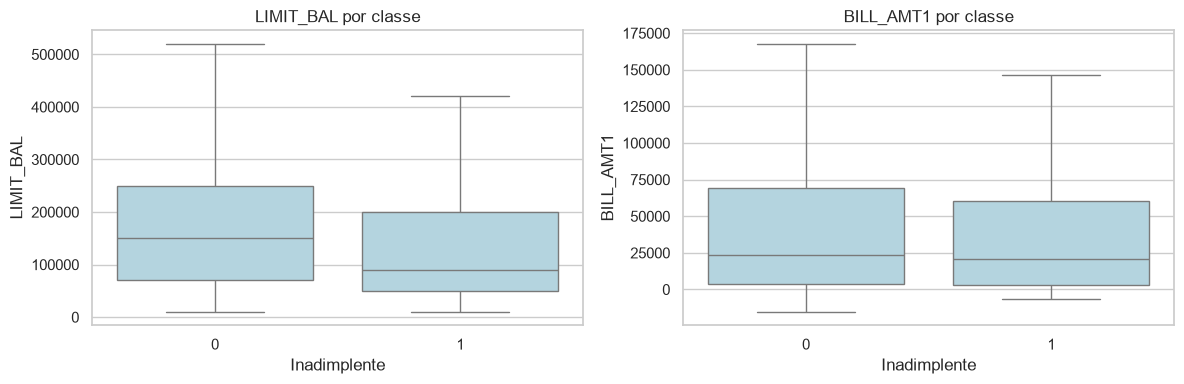

In [42]:
# Comparação descritiva entre grupos de inadimplência (treino)
indicadores = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
resumo_classes = (
    eda_treino.groupby("inadimplente")[indicadores]
    .agg(["median", "mean"])
    .round(2)
)
display(resumo_classes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, coluna in zip(axes, ["LIMIT_BAL", "BILL_AMT1"]):
    sns.boxplot(data=eda_treino, x="inadimplente", y=coluna,
                ax=ax, showfliers=False, color="lightblue")
    ax.set_title(f"{coluna} por classe")
    ax.set_xlabel("Inadimplente")
plt.tight_layout()
plt.show()

### Diferenças descritivas entre clientes

A tabela compara média e mediana de variáveis-chave nos grupos adimplente (`0`) e inadimplente (`1`). Os gráficos mostram tendências sem os pontos extremos visíveis; eles **não removem** registros. Diferenças observadas não comprovam causalidade ou utilidade preditiva isolada. Testes formais e intervalos de confiança ficam para o notebook estatístico. **Anotar as diferenças observadas após execução.**

## Conclusões e próximos passos

**Achados já confirmados nos resultados salvos:** 30.000 registros, 24 colunas incluindo o alvo, 0 valores ausentes, 35 duplicatas completas, 22,12% de inadimplentes e *split* com perfis idênticos agrupados. O status de pagamento de setembro (`PAY_0`) mostra associação exploratória importante com a inadimplência no mês seguinte.

**Pontos que dependem de executar as células acrescentadas:** distribuição dos valores financeiros, frequência dos extremos, matriz de correlação e diferenças de valores entre grupos. Não afirmar resultados numéricos desses blocos antes de executá-los.

**Decisões para a modelagem:**
1. Manter registros duplicados por enquanto, pois não há identificador individual na matriz de atributos; documentar essa limitação.
2. Não tratar códigos de `EDUCATION`, `MARRIAGE` ou `PAY_*` como valores ausentes automaticamente; definir regras de recodificação documentadas.
3. Na segmentação, usar somente atributos apropriados ao perfil financeiro, sem a variável-alvo; escalar atributos dentro do treino e caracterizar os grupos com inadimplência **depois** de agrupá-los.
4. Na classificação, reservar o teste para avaliação final e aplicar transformações e seleção de limiar dentro de treino/validação.
5. Avaliar diferenças por grupos demográficos e as limitações de generalizar dados históricos de Taiwan para outros contextos. Este estudo não deve ser usado para decisões reais de crédito.

**Próximo notebook:** `02_segmentacao.ipynb` — K-Means, escolha de *k* por cotovelo/silhouette, visualização e perfil dos segmentos.